# MECHA, 4: sensitivity analysis

**What you will learn:** rank MECHA's parameters by their effect on kr, first one at a time, then all together by
random sampling.

**You need:** tutorials 2 and 3. **Run time:** about 30 seconds.

A **sensitivity analysis** answers: *which parameters matter most for this output?* It tells which parameters need
an accurate measurement or calibration, and which can stay at their defaults.

## 1. One at a time

Each parameter is changed by −10 % and +10 % around its default, the others kept at their defaults, and the
relative change of kr is recorded. The barrier conductivities (10⁻¹⁶, a near-zero placeholder) and `thickness`
(not used with GRANAP's own wall thicknesses) are left out.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.mecha.simulation import parameters, simulate

studied = ["kw", "kmb", "kaqp", "kpl", "kaqp_endo_factor", "kaqp_exo_factor", "kaqp_cortex_factor",
           "kaqp_stele_factor"]
defaults = parameters().set_index("name")["value"]
reference = simulate().summary["kr"]
effects = {}
for name in studied:
    low = simulate({name: 0.9 * defaults[name]}).summary["kr"]
    high = simulate({name: 1.1 * defaults[name]}).summary["kr"]
    effects[name] = (high - low) / reference          # the relative change over the 20 % range
effects = pd.Series(effects).sort_values()
effects.round(4)

kaqp_exo_factor       0.0001
kaqp_stele_factor     0.0023
kaqp_cortex_factor    0.0043
kmb                   0.0070
kw                    0.0449
kpl                   0.0478
kaqp_endo_factor      0.0938
kaqp                  0.1005
dtype: float64

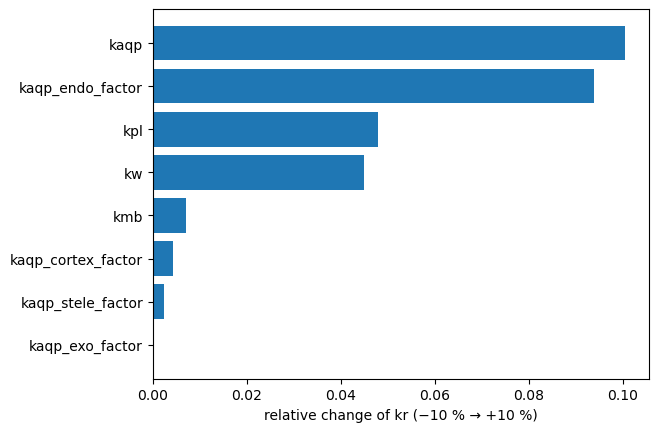

In [2]:
plt.barh(effects.index, effects.values)
plt.xlabel("relative change of kr (−10 % → +10 %)");

**Reading the bars.** A bar of 0.1 means kr changes by 10 % when the parameter goes from −10 % to +10 %.

- The aquaporins, `kaqp`, matter most, and almost all of their effect comes from the endodermis
  (`kaqp_endo_factor`): its membranes are where the water must cross.
- The plasmodesmata (`kpl`) and the walls (`kw`) come next.
- The aquaporins of the cortex, the exodermis and the stele hardly matter: there, the walls carry the water.

## 2. All together: random sampling

Changing one parameter at a time explores only a cross around the defaults. Here four parameters vary together,
each between half and twice its default, so that interactions (tutorial 3) show. A **Latin hypercube** draws 40
combinations covering each range evenly. Since the factors are multiplicative, they are sampled on a logarithmic
scale. A linear regression of log kr on the log parameters then gives each parameter's **elasticity**: the % change
of kr for a 1 % change of the parameter. **R²** says how well this linear description fits.

Dedicated libraries (for example SALib) offer more methods (Morris, Sobol). The principle stays the same: sample the
parameters, run the model, relate the outputs to the parameters.

In [3]:
from scipy.stats import qmc

sampled = ["kw", "kmb", "kaqp", "kpl"]
log_factors = qmc.scale(qmc.LatinHypercube(d=len(sampled), seed=0).random(40), [np.log(0.5)] * 4, [np.log(2.)] * 4)
kr = np.array([simulate({name: defaults[name] * np.exp(f) for name, f in zip(sampled, row)}).summary["kr"]
               for row in log_factors])

design = np.column_stack([np.ones(len(kr)), log_factors])
coefficients, *_ = np.linalg.lstsq(design, np.log(kr), rcond=None)
fitted = design @ coefficients
r2 = 1 - np.sum((np.log(kr) - fitted) ** 2) / np.sum((np.log(kr) - np.log(kr).mean()) ** 2)
print("elasticity of kr:", {name: round(c, 3) for name, c in zip(sampled, coefficients[1:])}, f"R² {r2:.3f}")

elasticity of kr: {'kw': np.float64(0.228), 'kmb': np.float64(0.056), 'kaqp': np.float64(0.492), 'kpl': np.float64(0.237)} R² 0.979


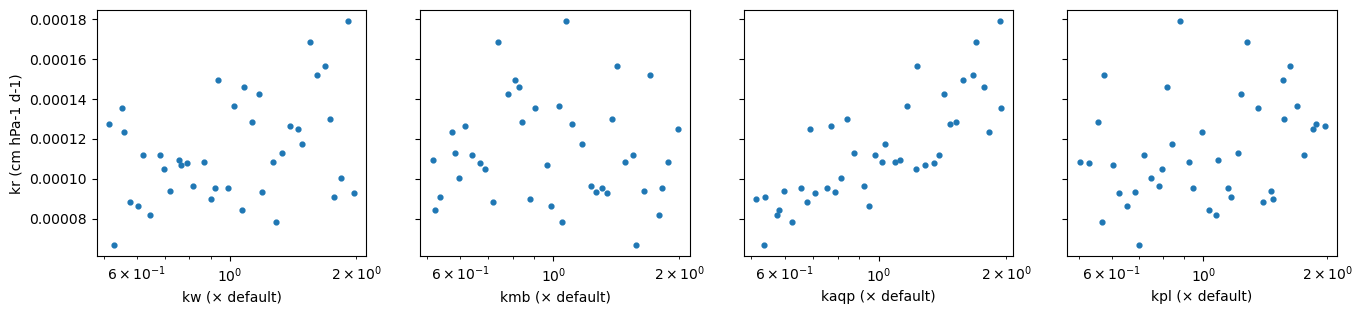

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, name, column in zip(axes, sampled, log_factors.T):
    ax.scatter(np.exp(column), kr, s=12)
    ax.set_xscale("log"); ax.set_xlabel(f"{name} (× default)")
axes[0].set_ylabel("kr (cm hPa-1 d-1)");

The elasticities rank the parameters as the one-at-a-time analysis did, over a much wider range. A high R² means
the effects nearly add up on a logarithmic scale. The interaction seen in tutorial 3 appears only at the extremes
(× 0.1 and × 10).

## Try it yourself

1. Repeat the one-at-a-time analysis with a suberized endodermis (`simulate({...}, barrier=3)`). Which parameters
   matter now?
2. Add `kaqp_endo_factor` to the random sample. How do its elasticity and `kaqp`'s share the effect?

**Next:** `05_experimental_data.ipynb`.